In [1]:
!pip install pgmpy
import os
import warnings
warnings.filterwarnings("ignore")
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator

out_dir = "outputs_p1"
os.makedirs(out_dir, exist_ok=True)
rand_seed = 42
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

var_domains = {
    "Weather": ["Hot", "Mild", "Cold"],
    "DayType": ["Weekday", "Weekend"],
    "Occupancy": ["High", "Low"],
    "AC": ["On", "Off"],
    "Load": ["Heavy", "Light"],
    "Energy": ["High", "Low"],
}
graph_edges = [("DayType", "Occupancy"),
               ("Weather", "AC"), ("Occupancy", "AC"),
               ("Occupancy", "Load"),
               ("AC", "Energy"), ("Load", "Energy")]
node_order = ["Weather", "DayType", "Occupancy", "AC", "Load", "Energy"]
parent_map = {
    "Weather": [], "DayType": [],
    "Occupancy": ["DayType"],
    "AC": ["Weather", "Occupancy"],
    "Load": ["Occupancy"],
    "Energy": ["AC", "Load"],
}

p_w_prior = {"Hot": 0.50, "Mild": 0.30, "Cold": 0.20}
p_d_prior = {"Weekday": 0.70, "Weekend": 0.30}
p_occ_hi = {("Weekday",): 0.45, ("Weekend",): 0.80}
p_ac_on = {("Hot", "High"): 0.90, ("Hot", "Low"): 0.60,
           ("Mild", "High"): 0.40, ("Mild", "Low"): 0.15,
           ("Cold", "High"): 0.10, ("Cold", "Low"): 0.05}
p_ld_hvy = {("High",): 0.75, ("Low",): 0.35}
p_en_hi = {("On", "Heavy"): 0.92, ("On", "Light"): 0.68,
           ("Off", "Heavy"): 0.55, ("Off", "Light"): 0.12}
first_prob_map = {"Occupancy": p_occ_hi, "AC": p_ac_on, "Load": p_ld_hvy, "Energy": p_en_hi}


def make_cpd(node_var, prob_lookup):
    parents = parent_map[node_var]
    combos = list(itertools.product(*[var_domains[p] for p in parents]))
    first_vals = [prob_lookup[cfg] for cfg in combos]
    cpt_matrix = [first_vals, [1 - p for p in first_vals]]
    return TabularCPD(
        node_var, 2, cpt_matrix,
        evidence=parents or None,
        evidence_card=[len(var_domains[p]) for p in parents] or None,
        state_names={node_var: var_domains[node_var], **{p: var_domains[p] for p in parents}}
    )


def build_expert_model():
    net = DiscreteBayesianNetwork(graph_edges)
    net.add_cpds(
        TabularCPD("Weather", 3, [[p_w_prior[s]] for s in var_domains["Weather"]],
                   state_names={"Weather": var_domains["Weather"]}),
        TabularCPD("DayType", 2, [[p_d_prior[s]] for s in var_domains["DayType"]],
                   state_names={"DayType": var_domains["DayType"]}),
        make_cpd("Occupancy", p_occ_hi),
        make_cpd("AC", p_ac_on),
        make_cpd("Load", p_ld_hvy),
        make_cpd("Energy", p_en_hi),
    )
    return net


def draw_network(bn_model, save_path, plot_title):
    di_graph = nx.DiGraph(bn_model.edges())
    layout_coords = {"Weather": (0, 2), "DayType": (3, 2), "Occupancy": (3, 1),
                     "AC": (1, 0.5), "Load": (4, 0.5), "Energy": (2.5, -0.5)}
    plt.figure(figsize=(8, 5))
    nx.draw(di_graph, layout_coords, with_labels=True, node_color="#a8d0f0", node_size=3200,
            font_size=10, font_weight="bold", arrowsize=22, edge_color="#444")
    plt.title(plot_title)
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()


def run_queries(target_bn):
    engine = VariableElimination(target_bn)
    results = {}
    for q_code, (q_var, q_st, ev_map) in query_cases.items():
        factor_dist = engine.query([q_var], evidence=ev_map, show_progress=False)
        results[q_code] = float(factor_dist.get_value(**{q_var: q_st}))
    return results


def cond_dist(node_var, sampled_ctx):
    if node_var == "Weather":
        return p_w_prior
    if node_var == "DayType":
        return p_d_prior
    par_key = tuple(sampled_ctx[p] for p in parent_map[node_var])
    p_primary = first_prob_map[node_var][par_key]
    state_0, state_1 = var_domains[node_var]
    return {state_0: p_primary, state_1: 1 - p_primary}


def ancestral_sample(num_samples, rand_seed):
    gen = np.random.default_rng(rand_seed)
    records = []
    for _ in range(num_samples):
        inst = {}
        for node in node_order:
            dist_map = cond_dist(node, inst)
            possible_states, state_probs = list(dist_map.keys()), list(dist_map.values())
            inst[node] = possible_states[gen.choice(len(possible_states), p=state_probs)]
        records.append(inst)
    return pd.DataFrame(records, columns=node_order)


def learn(sample_df, fitting_strategy):
    learned_bn = DiscreteBayesianNetwork(graph_edges)
    if fitting_strategy == "MLE":
        estimator = MaximumLikelihoodEstimator(learned_bn, sample_df, state_names=var_domains)
        cpd_list = estimator.get_parameters()
    else:
        estimator = BayesianEstimator(learned_bn, sample_df, state_names=var_domains)
        cpd_list = estimator.get_parameters(prior_type="BDeu", equivalent_sample_size=10)
    learned_bn.add_cpds(*cpd_list)
    learned_bn.check_model()
    return learned_bn


def ac_table(bn_model):
    ac_factor = bn_model.get_cpds("AC")
    entries = []
    for w_val in var_domains["Weather"]:
        for o_val in var_domains["Occupancy"]:
            entries.append(((w_val, o_val), float(ac_factor.get_value(AC="On", Weather=w_val, Occupancy=o_val))))
    return pd.Series(dict(entries))




   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 7.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


## Problem 1: Smart Home Energy Consumption using Bayesian Networks
### Part A: Expert Bayesian Network

PART A  -  EXPERT NETWORK
  CPT Weather    OK  (all 1 parent configs sum to 1)
  CPT DayType    OK  (all 1 parent configs sum to 1)
  CPT Occupancy  OK  (all 2 parent configs sum to 1)
  CPT AC         OK  (all 6 parent configs sum to 1)
  CPT Load       OK  (all 2 parent configs sum to 1)
  CPT Energy     OK  (all 4 parent configs sum to 1)


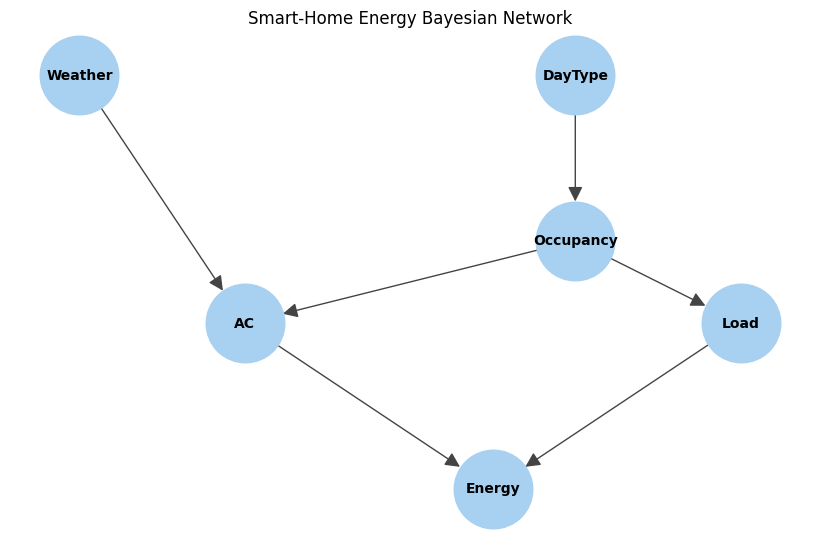


Expert model inference:
  Q1: P(E=High)                        = 0.5806
  Q2: P(E=High | W=Hot)                = 0.7063
  Q3: P(E=High | D=Weekend)            = 0.6402
  Q4: P(E=High | W=Cold, O=High)       = 0.4843
  Q5: P(W=Hot | E=High)                = 0.6082
  Q6: P(AC=On | E=High)                = 0.6929
  Q7: P(AC=On | E=High, L=Heavy)       = 0.6499


In [2]:
print("=" * 70, "\nPART A  -  EXPERT NETWORK\n" + "=" * 70)
exp_net = build_expert_model()
assert exp_net.check_model()
for factor in exp_net.get_cpds():
    col_sums = factor.get_values().sum(axis=0)
    assert np.allclose(col_sums, 1.0)
    print(f"  CPT {factor.variable:<10s} OK  (all {len(col_sums)} parent configs sum to 1)")

draw_network(exp_net, f"{out_dir}/bayesian_network.png", "Smart-Home Energy Bayesian Network")

query_cases = {
    "Q1": ("Energy", "High", {}),
    "Q2": ("Energy", "High", {"Weather": "Hot"}),
    "Q3": ("Energy", "High", {"DayType": "Weekend"}),
    "Q4": ("Energy", "High", {"Weather": "Cold", "Occupancy": "High"}),
    "Q5": ("Weather", "Hot", {"Energy": "High"}),
    "Q6": ("AC", "On", {"Energy": "High"}),
    "Q7": ("AC", "On", {"Energy": "High", "Load": "Heavy"}),
}
query_labels = {
    "Q1": "P(E=High)",
    "Q2": "P(E=High | W=Hot)",
    "Q3": "P(E=High | D=Weekend)",
    "Q4": "P(E=High | W=Cold, O=High)",
    "Q5": "P(W=Hot | E=High)",
    "Q6": "P(AC=On | E=High)",
    "Q7": "P(AC=On | E=High, L=Heavy)",
}

exp_out = run_queries(exp_net)
print("\nExpert model inference:")
for q_k, q_val in exp_out.items():
    print(f"  {q_k}: {query_labels[q_k]:<32s} = {q_val:.4f}")



### Q1 by hand: P(Energy = High)

**Step 1: Occupancy**

P(O=High) = 0.70 × 0.45 + 0.30 × 0.80 = 0.315 + 0.240 = **0.555**, so P(O=Low) = **0.445**

**Step 2: AC given Occupancy (summing out Weather)**

P(A=On | O=High) = 0.50 × 0.90 + 0.30 × 0.40 + 0.20 × 0.10 = **0.590**, so P(A=Off | O=High) = 0.410

P(A=On | O=Low) = 0.50 × 0.60 + 0.30 × 0.15 + 0.20 × 0.05 = **0.355**, so P(A=Off | O=Low) = 0.645

**Step 3: P(E=High | O) = Σ P(A|O) · P(L|O) · P(E=High | A, L)**

For O = High (P(Heavy) = 0.75, P(Light) = 0.25):

| A | L | P(A\|O) · P(L\|O) · P(E=High\|A,L) | Term |
|---|---|---|---|
| On | Heavy | 0.590 × 0.75 × 0.92 | 0.407100 |
| On | Light | 0.590 × 0.25 × 0.68 | 0.100300 |
| Off | Heavy | 0.410 × 0.75 × 0.55 | 0.169125 |
| Off | Light | 0.410 × 0.25 × 0.12 | 0.012300 |

P(E=High | O=High) = **0.688825**

For O = Low (P(Heavy) = 0.35, P(Light) = 0.65):

| A | L | P(A\|O) · P(L\|O) · P(E=High\|A,L) | Term |
|---|---|---|---|
| On | Heavy | 0.355 × 0.35 × 0.92 | 0.114310 |
| On | Light | 0.355 × 0.65 × 0.68 | 0.156910 |
| Off | Heavy | 0.645 × 0.35 × 0.55 | 0.1241625 |
| Off | Light | 0.645 × 0.65 × 0.12 | 0.050310 |

P(E=High | O=Low) = **0.4456925**

**Step 4: Sum over Occupancy**

P(E=High) = 0.555 × 0.688825 + 0.445 × 0.4456925 = 0.382298 + 0.198333 = **0.580631**

This matches the value from the code (Q1 = 0.580631).

### Q6 vs Q7: Explaining away

P(AC=On | E=High) = **0.6929**, while P(AC=On | E=High, Load=Heavy) = **0.6499**. Once we also know the load was heavy, the probability of the AC being on drops by about 0.043.

AC and Load both feed into Energy, so Energy is a collider. If we only know that consumption was high, the AC being on is a very likely reason for it. But if we also know the appliance load was heavy, that already explains a good part of the high consumption, so the AC doesn't need to be on to account for it. The two causes compete, which is exactly what explaining away means.

In [3]:
print("\nExplaining away:")
print(f"  Q6 P(AC=On | E=High)               = {exp_out['Q6']:.4f}")
print(f"  Q7 P(AC=On | E=High, Load=Heavy)   = {exp_out['Q7']:.4f}")
print(f"  Change (Q7 - Q6)                   = {exp_out['Q7'] - exp_out['Q6']:+.4f}")

print("\nQ1 by hand:")
p_occ_h_hand = sum(p_d_prior[d] * p_occ_hi[(d,)] for d in p_d_prior)
p_occ_marg = {"High": p_occ_h_hand, "Low": 1 - p_occ_h_hand}
print(f"  P(O=High) = 0.70*0.45 + 0.30*0.80 = {p_occ_h_hand:.4f};  P(O=Low) = {1 - p_occ_h_hand:.4f}")
p_ac_by_occ = {}
for o_st in ["High", "Low"]:
    p_on_val = sum(p_w_prior[w] * p_ac_on[(w, o_st)] for w in p_w_prior)
    p_ac_by_occ[o_st] = {"On": p_on_val, "Off": 1 - p_on_val}
    print(f"  P(A=On | O={o_st}) = " +
          " + ".join(f"{p_w_prior[w]:.2f}*{p_ac_on[(w, o_st)]:.2f}" for w in p_w_prior) + f" = {p_on_val:.4f}")
p_e_by_occ = {}
manual_tot = 0.0
for o_st in ["High", "Low"]:
    p_ld_val = p_ld_hvy[(o_st,)]
    sub_val = 0.0
    print(f"  --- O = {o_st} : sum over (A, L) of P(A|O) P(L|O) P(E=High|A,L)")
    for a_st in ["On", "Off"]:
        for l_st, p_ld_inst in [("Heavy", p_ld_val), ("Light", 1 - p_ld_val)]:
            p_e_inst = p_en_hi[(a_st, l_st)]
            prod_term = p_ac_by_occ[o_st][a_st] * p_ld_inst * p_e_inst
            sub_val += prod_term
            print(f"      A={a_st:<3s} L={l_st:<5s}: {p_ac_by_occ[o_st][a_st]:.4f} * {p_ld_inst:.2f} * {p_e_inst:.2f} = {prod_term:.6f}")
    p_e_by_occ[o_st] = sub_val
    print(f"      P(E=High | O={o_st}) = {sub_val:.6f}")
    manual_tot += p_occ_marg[o_st] * sub_val
print(f"  P(E=High) = {p_occ_marg['High']:.3f}*{p_e_by_occ['High']:.6f} + "
      f"{p_occ_marg['Low']:.3f}*{p_e_by_occ['Low']:.6f} = {manual_tot:.6f}")
print(f"  Code (Q1)                          = {exp_out['Q1']:.6f}")
assert abs(manual_tot - exp_out["Q1"]) < 1e-9
print("  MATCH: hand calculation == code")




Explaining away:
  Q6 P(AC=On | E=High)               = 0.6929
  Q7 P(AC=On | E=High, Load=Heavy)   = 0.6499
  Change (Q7 - Q6)                   = -0.0430

Q1 by hand:
  P(O=High) = 0.70*0.45 + 0.30*0.80 = 0.5550;  P(O=Low) = 0.4450
  P(A=On | O=High) = 0.50*0.90 + 0.30*0.40 + 0.20*0.10 = 0.5900
  P(A=On | O=Low) = 0.50*0.60 + 0.30*0.15 + 0.20*0.05 = 0.3550
  --- O = High : sum over (A, L) of P(A|O) P(L|O) P(E=High|A,L)
      A=On  L=Heavy: 0.5900 * 0.75 * 0.92 = 0.407100
      A=On  L=Light: 0.5900 * 0.25 * 0.68 = 0.100300
      A=Off L=Heavy: 0.4100 * 0.75 * 0.55 = 0.169125
      A=Off L=Light: 0.4100 * 0.25 * 0.12 = 0.012300
      P(E=High | O=High) = 0.688825
  --- O = Low : sum over (A, L) of P(A|O) P(L|O) P(E=High|A,L)
      A=On  L=Heavy: 0.3550 * 0.35 * 0.92 = 0.114310
      A=On  L=Light: 0.3550 * 0.65 * 0.68 = 0.156910
      A=Off L=Heavy: 0.6450 * 0.35 * 0.55 = 0.124162
      A=Off L=Light: 0.6450 * 0.65 * 0.12 = 0.050310
      P(E=High | O=Low) = 0.445693
  P(E=High) = 0.

### Part B: Conditional Independence (d-separation)

**1. Weather ⊥ DayType: holds.** The only path between them is Weather → AC ← Occupancy ← DayType. AC is a collider, and neither AC nor its descendant Energy is observed, so the path is blocked. This agrees with the numbers: P(W=Hot) = 0.5000 and P(W=Hot | D=Weekend) = 0.5000.

**2. Weather ⊥ DayType | Energy: does not hold.** Energy is a descendant of the collider AC, so observing it opens the path Weather → AC ← Occupancy ← DayType. Numerically, P(W=Hot | E=High) = 0.6082 but P(W=Hot | E=High, D=Weekend) = 0.5998, so the two are not equal.

**3. Weather ⊥ Load | Occupancy: holds.** On the path Weather → AC ← Occupancy → Load, AC is an unobserved collider and Occupancy is an observed fork, so it is blocked. The other path, Weather → AC → Energy ← Load, is blocked at the unobserved collider Energy. Numerically, P(W=Hot | O=High) = 0.5000 and P(W=Hot | O=High, L=Heavy) = 0.5000.

In [4]:
print("\n" + "=" * 70, "\nPART B  -  d-SEPARATION\n" + "=" * 70)
dsep_queries = [
    ("Weather", "DayType", []),
    ("Weather", "DayType", ["Energy"]),
    ("Weather", "Load", ["Occupancy"]),
]
for node_x, node_y, cond_z in dsep_queries:
    is_sep = not exp_net.is_dconnected(node_x, node_y, observed=cond_z)
    cond_str = f" | {', '.join(cond_z)}" if cond_z else ""
    print(f"  {node_x} _||_ {node_y}{cond_str}  ->  {'HOLDS' if is_sep else 'DOES NOT HOLD'}")

ve_engine = VariableElimination(exp_net)


def calc_prob(var, target_state, ev_dict):
    return float(ve_engine.query([var], evidence=ev_dict, show_progress=False).get_value(**{var: target_state}))


print("\nNumerical verification:")
print("  (1) Weather _||_ DayType")
print(f"      P(W=Hot)                         = {calc_prob('Weather', 'Hot', {}):.4f}")
print(f"      P(W=Hot | D=Weekend)             = {calc_prob('Weather', 'Hot', {'DayType': 'Weekend'}):.4f}")
print("  (2) Weather _||_ DayType | Energy")
print(f"      P(W=Hot | E=High)                = {calc_prob('Weather', 'Hot', {'Energy': 'High'}):.4f}")
print(f"      P(W=Hot | E=High, D=Weekend)     = {calc_prob('Weather', 'Hot', {'Energy': 'High', 'DayType': 'Weekend'}):.4f}")
print("  (3) Weather _||_ Load | Occupancy")
print(f"      P(W=Hot | O=High)                = {calc_prob('Weather', 'Hot', {'Occupancy': 'High'}):.4f}")
print(f"      P(W=Hot | O=High, L=Heavy)       = {calc_prob('Weather', 'Hot', {'Occupancy': 'High', 'Load': 'Heavy'}):.4f}")




PART B  -  d-SEPARATION
  Weather _||_ DayType  ->  HOLDS
  Weather _||_ DayType | Energy  ->  DOES NOT HOLD
  Weather _||_ Load | Occupancy  ->  HOLDS

Numerical verification:
  (1) Weather _||_ DayType
      P(W=Hot)                         = 0.5000
      P(W=Hot | D=Weekend)             = 0.5000
  (2) Weather _||_ DayType | Energy
      P(W=Hot | E=High)                = 0.6082
      P(W=Hot | E=High, D=Weekend)     = 0.5998
  (3) Weather _||_ Load | Occupancy
      P(W=Hot | O=High)                = 0.5000
      P(W=Hot | O=High, L=Heavy)       = 0.5000


### Part C: Synthetic Data Generation

In [5]:
print("\n" + "=" * 70, f"\nPART C  -  ANCESTRAL SAMPLING (seed = {rand_seed})\n" + "=" * 70)
sample_counts = [500, 5000, 20000]
data_store = {}
for cnt in sample_counts:
    df_samp = ancestral_sample(cnt, rand_seed)
    data_store[cnt] = df_samp
    print(f"\n--- Dataset n = {cnt} ---")
    print("Empirical Weather frequency (true: Hot .50, Mild .30, Cold .20):")
    print(df_samp["Weather"].value_counts(normalize=True).reindex(var_domains["Weather"]).round(4).to_string())
    print("Counts per (Weather, Occupancy):")
    print(pd.crosstab(df_samp["Weather"], df_samp["Occupancy"]).reindex(var_domains["Weather"]).to_string())
    df_samp.to_csv(f"{out_dir}/samples_{cnt}.csv", index=False)




PART C  -  ANCESTRAL SAMPLING (seed = 42)

--- Dataset n = 500 ---
Empirical Weather frequency (true: Hot .50, Mild .30, Cold .20):
Weather
Hot     0.510
Mild    0.286
Cold    0.204
Counts per (Weather, Occupancy):
Occupancy  High  Low
Weather             
Hot         155  100
Mild         75   68
Cold         51   51

--- Dataset n = 5000 ---
Empirical Weather frequency (true: Hot .50, Mild .30, Cold .20):
Weather
Hot     0.4992
Mild    0.3020
Cold    0.1988
Counts per (Weather, Occupancy):
Occupancy  High   Low
Weather              
Hot        1402  1094
Mild        823   687
Cold        558   436

--- Dataset n = 20000 ---
Empirical Weather frequency (true: Hot .50, Mild .30, Cold .20):
Weather
Hot     0.4953
Mild    0.3058
Cold    0.1989
Counts per (Weather, Occupancy):
Occupancy  High   Low
Weather              
Hot        5520  4386
Mild       3416  2700
Cold       2228  1750


### Part D: Learning from Data

In [6]:
print("\n" + "=" * 70, "\nPART D  -  LEARNING\n" + "=" * 70)
fit_models, fit_res = {}, {}
for cnt, cur_df in data_store.items():
    fit_models[cnt] = {"MLE": learn(cur_df, "MLE"), "BDeu": learn(cur_df, "BDeu")}
    fit_res[cnt] = {method: run_queries(m_obj) for method, m_obj in fit_models[cnt].items()}
    cpt_df = pd.DataFrame({
        "n(W,O)": cur_df.groupby(["Weather", "Occupancy"]).size().reindex(
            pd.MultiIndex.from_product([var_domains["Weather"], var_domains["Occupancy"]])).fillna(0).astype(int),
        "Expert": ac_table(exp_net),
        "MLE": ac_table(fit_models[cnt]["MLE"]),
        "BDeu": ac_table(fit_models[cnt]["BDeu"]),
    })
    cpt_df.index.names = ["Weather", "Occupancy"]
    print(f"\nP(AC=On | Weather, Occupancy)  -  n = {cnt}")
    print(cpt_df.round(4).to_string())
    inf_df = pd.DataFrame({
        "Query": [query_labels[q] for q in query_cases],
        "MLE": [fit_res[cnt]["MLE"][q] for q in query_cases],
        "BDeu": [fit_res[cnt]["BDeu"][q] for q in query_cases],
    }, index=list(query_cases))
    print(f"\nLearned-model inference (Q1-Q7)  -  n = {cnt}")
    print(inf_df.round(4).to_string())




PART D  -  LEARNING

P(AC=On | Weather, Occupancy)  -  n = 500
                   n(W,O)  Expert     MLE    BDeu
Weather Occupancy                                
Hot     High          155    0.90  0.8516  0.8479
        Low           100    0.60  0.6600  0.6574
Mild    High           75    0.40  0.3600  0.3630
        Low            68    0.15  0.1765  0.1842
Cold    High           51    0.10  0.0980  0.1108
        Low            51    0.05  0.0196  0.0348

Learned-model inference (Q1-Q7)  -  n = 500
                         Query     MLE    BDeu
Q1                   P(E=High)  0.5570  0.5559
Q2           P(E=High | W=Hot)  0.7050  0.6991
Q3       P(E=High | D=Weekend)  0.6092  0.6046
Q4  P(E=High | W=Cold, O=High)  0.4203  0.4268
Q5           P(W=Hot | E=High)  0.6455  0.6370
Q6           P(AC=On | E=High)  0.7280  0.7236
Q7  P(AC=On | E=High, L=Heavy)  0.6584  0.6560

P(AC=On | Weather, Occupancy)  -  n = 5000
                   n(W,O)  Expert     MLE    BDeu
Weather Occupancy    

### Part E: Comparative Analysis


PART E  -  COMPARISON

--- Dataset size 500 ---
       Expert     MLE  Bayesian  |Diff| MLE  |Diff| Bayesian
Query                                                       
Q1     0.5806  0.5570    0.5559      0.0237           0.0247
Q2     0.7063  0.7050    0.6991      0.0013           0.0072
Q3     0.6402  0.6092    0.6046      0.0310           0.0356
Q4     0.4843  0.4203    0.4268      0.0639           0.0575
Q5     0.6082  0.6455    0.6370      0.0373           0.0288
Q6     0.6929  0.7280    0.7236      0.0351           0.0307
Q7     0.6499  0.6584    0.6560      0.0085           0.0061
Mean |Diff|: MLE = 0.02868   Bayesian = 0.02722

--- Dataset size 5000 ---
       Expert     MLE  Bayesian  |Diff| MLE  |Diff| Bayesian
Query                                                       
Q1     0.5806  0.5794    0.5793      0.0012           0.0014
Q2     0.7063  0.7034    0.7028      0.0029           0.0035
Q3     0.6402  0.6399    0.6393      0.0003           0.0009
Q4     0.4843  0.4860 

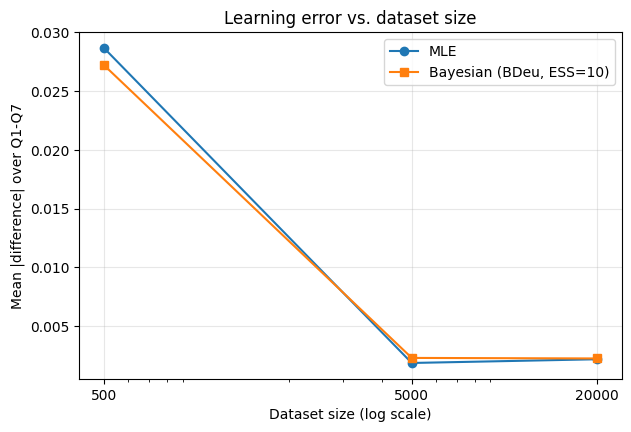


Mean |Diff| per dataset size:
           MLE     BDeu
500    0.02868  0.02722
5000   0.00187  0.00230
20000  0.00219  0.00226

Largest error at n=500 (|Diff| MLE): Q4  P(E=High | W=Cold, O=High)  error = 0.0639

Largest error at n=500 (|Diff| Bayesian): Q4  P(E=High | W=Cold, O=High)  error = 0.0575
Evidence frequency in the 500-sample dataset:
  (W=Cold, O=High)  rows: 51
  (E=High)          rows: 280
  (E=High, L=Heavy) rows: 198
  (Cold, High, AC=On) rows: 5


In [7]:
print("\n" + "=" * 70, "\nPART E  -  COMPARISON\n" + "=" * 70)
mad_scores = {"MLE": [], "BDeu": []}
comp_dfs = {}
for cnt in sample_counts:
    table_rows = []
    for q_id in query_cases:
        e_val = exp_out[q_id]
        ml_val = fit_res[cnt]["MLE"][q_id]
        bd_val = fit_res[cnt]["BDeu"][q_id]
        table_rows.append({"Query": q_id, "Expert": e_val, "MLE": ml_val, "Bayesian": bd_val,
                           "|Diff| MLE": abs(e_val - ml_val), "|Diff| Bayesian": abs(e_val - bd_val)})
    res_df = pd.DataFrame(table_rows).set_index("Query")
    comp_dfs[cnt] = res_df
    mad_scores["MLE"].append(res_df["|Diff| MLE"].mean())
    mad_scores["BDeu"].append(res_df["|Diff| Bayesian"].mean())
    print(f"\n--- Dataset size {cnt} ---")
    print(res_df.round(4).to_string())
    print(f"Mean |Diff|: MLE = {res_df['|Diff| MLE'].mean():.5f}   Bayesian = {res_df['|Diff| Bayesian'].mean():.5f}")
    res_df.round(5).to_csv(f"{out_dir}/comparison_{cnt}.csv")

plt.figure(figsize=(7, 4.5))
plt.plot(sample_counts, mad_scores["MLE"], "o-", label="MLE")
plt.plot(sample_counts, mad_scores["BDeu"], "s-", label="Bayesian (BDeu, ESS=10)")
plt.xscale("log")
plt.xticks(sample_counts, [str(s) for s in sample_counts])
plt.xlabel("Dataset size (log scale)")
plt.ylabel("Mean |difference| over Q1-Q7")
plt.title("Learning error vs. dataset size")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig(f"{out_dir}/mean_abs_diff.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("\nMean |Diff| per dataset size:")
print(pd.DataFrame(mad_scores, index=sample_counts).round(5).to_string())

df_500 = comp_dfs[500]
for score_col in ["|Diff| MLE", "|Diff| Bayesian"]:
    top_q = df_500[score_col].idxmax()
    print(f"\nLargest error at n=500 ({score_col}): {top_q}  {query_labels[top_q]}  error = {df_500.loc[top_q, score_col]:.4f}")
raw_500 = data_store[500]
print("Evidence frequency in the 500-sample dataset:")
print(f"  (W=Cold, O=High)  rows: {((raw_500.Weather == 'Cold') & (raw_500.Occupancy == 'High')).sum()}")
print(f"  (E=High)          rows: {(raw_500.Energy == 'High').sum()}")
print(f"  (E=High, L=Heavy) rows: {((raw_500.Energy == 'High') & (raw_500.Load == 'Heavy')).sum()}")
print(f"  (Cold, High, AC=On) rows: "
      f"{((raw_500.Weather == 'Cold') & (raw_500.Occupancy == 'High') & (raw_500.AC == 'On')).sum()}")



### Analysis

**Largest error at n = 500.** Q4, P(E=High | Weather=Cold, Occupancy=High), has the largest error (0.0639 for MLE, 0.0575 for Bayesian). Its evidence is rare in the data: only 51 of the 500 rows have (Cold, High), and AC=On shows up in just 5 of those. The learned P(AC=On | Cold, High) is therefore based on very little data and is noisy, and that noise goes straight into Q4. The other queries rely on combinations that occur much more often.

**Which estimator is better for small datasets.** The Bayesian estimator does slightly better at n = 500 (mean absolute difference 0.0272 versus 0.0287 for MLE). The BDeu prior adds pseudo-counts that pull sparse estimates toward more reasonable values and keep probabilities away from exactly 0 or 1. For example, the rare (Cold, Low) cell gets 0.0348 instead of the MLE value of 0.0196, against a true value of 0.05. MLE uses only the observed counts, so it swings more when counts are small. With more data the prior matters less and the two estimators give almost the same results.